# Tutorial 9 — Kymographs

A kymograph maps a viscoelastic quantity over two independent variables, for
example $\tan\delta(T, \omega)$ over temperature and angular frequency. It
shows at a glance where relaxation processes occur and how they move with
temperature or time, information that is spread over many curves in
conventional sweep plots.

## TORCh experiments

In a Thermally Optimised Ramped Chirp (TORCh) experiment, OWChirps are applied
continuously during a temperature ramp at rate $\dot T$ (Vadillo et al.,
2026). Each chirp is time-stamped, so one ramp yields a dense
$(T, \omega)$ data set. Here the change of the material is imposed by the
ramp rather than by its own kinetics. If the viscoelastic properties are
single-valued functions of temperature, the mutation number of Tutorial 6
becomes

$$
\lvert \mathrm{Mu} \rvert = T_\mathrm{owc}
\left\lvert\frac{\partial \ln g(\omega, T)}{\partial T}\right\rvert \dot T,
$$

(Tutorial 6), so the ramp rate and chirp duration must be chosen to keep
$\lvert \mathrm{Mu} \rvert \lesssim 0.15$, especially near thermal transitions where
$g$ changes steeply. For low-conductivity samples, the ramp must also be slow
compared with heat diffusion through the gap $H$: the diffusion time
$\tau_\mathrm{diff} = H^2 \rho C_p / k$, with density $\rho$, heat capacity
$C_p$ and thermal conductivity $k$, should be small compared with the mutation
time $\lambda_\mathrm{Mu}$, otherwise the sample develops a temperature gradient.

## The `Kymograph` transform

`Kymograph` collects the scattered $(x, y, z)$ points of all measurements and
interpolates them onto a regular `n_x` × `n_y` grid with
`scipy.interpolate.griddata`; `log_y=True` interpolates in
$\log_{10}\omega$. Each axis is looked up first among the dataset columns and
then among the measurement conditions, so either variable can go on either
axis; `log_x` and `log_y` grid and plot an axis in log scale. The result is a
piblin `TwoDimensionalDataset` with names and units attached.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.kymograph import Kymograph
from hermes_rheo.transforms.mutation_number import MutationNumber
from hermes_rheo.visualization import use_science_style

use_science_style()
DATA = Path("tutorial_data")

## Temperature–frequency map of $\tan\delta$

We use the TORCh ramp of Tutorial 6 (−50 to 150 °C, 10 s chirps). The file
already contains the moduli of every chirp; for raw chirp waveforms, prepend
`OWChirpAnalysis()` (Tutorial 3). Peaks in $\tan\delta$ mark relaxation
processes such as the glass transition, and their shift to higher frequency
with temperature reflects the shift factor $a_T$ (Tutorial 4).

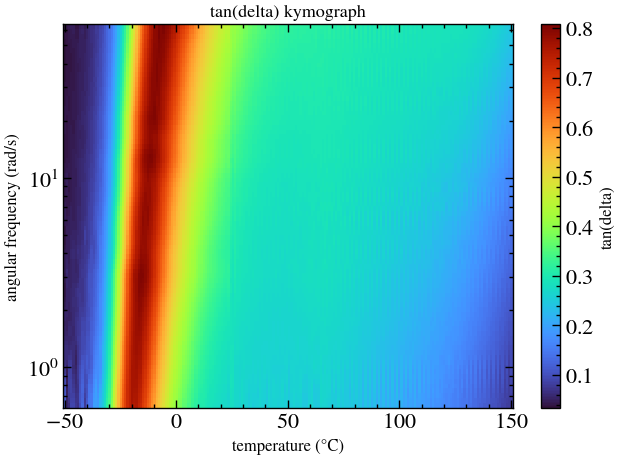

In [15]:
torch = read_file(DATA / "dhr30_trios_torch.txt",
                  file_reader=TriosRheoReader, create_composite_datasets=True)

tan_delta = Kymograph("tan(delta)", x="temperature", y="angular frequency")(torch)
fig, ax = tan_delta.plot(colormap="turbo")
plt.show()

The axes are chosen when the map is built. With frequency on $x$, set
`log_x=True` and `log_y=False`; the glass transition becomes a band that
rises in temperature with frequency.

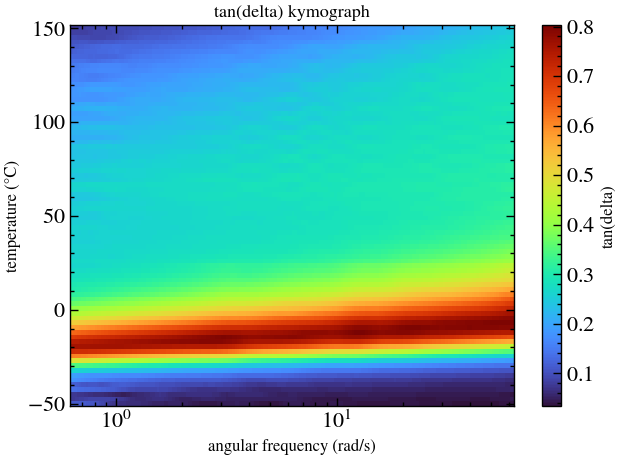

In [16]:
tan_delta_swapped = Kymograph("tan(delta)", x="angular frequency", y="temperature",
                              log_x=True, log_y=False)(torch)
fig, ax = tan_delta_swapped.plot(colormap="turbo")
plt.show()

## Other quantities and the colour scale

Any column can be mapped. The moduli span several decades, so `log_z=True`
uses a logarithmic colour scale; `vmin` and `vmax` fix the colour range, for
example to round decades or to compare several maps on a common scale.

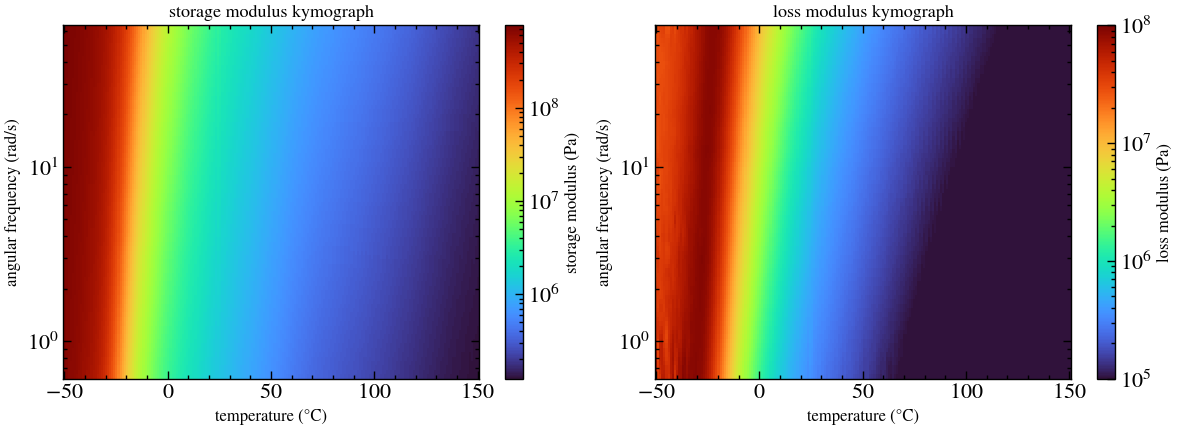

In [17]:
fig, (ax_storage, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.5))
Kymograph("storage modulus")(torch).plot(ax=ax_storage, colormap="turbo", log_z=True)
Kymograph("loss modulus")(torch).plot(ax=ax_loss, colormap="turbo", log_z=True,
                                     vmin=1e5, vmax=1e8)
plt.show()

## Slices

Slices through the grid at fixed $T$ give isothermal frequency sweeps; slices
at fixed $\omega$ give isochronal temperature sweeps, as from a dynamic
mechanical analysis (DMA) ramp, but both come from a single experiment.

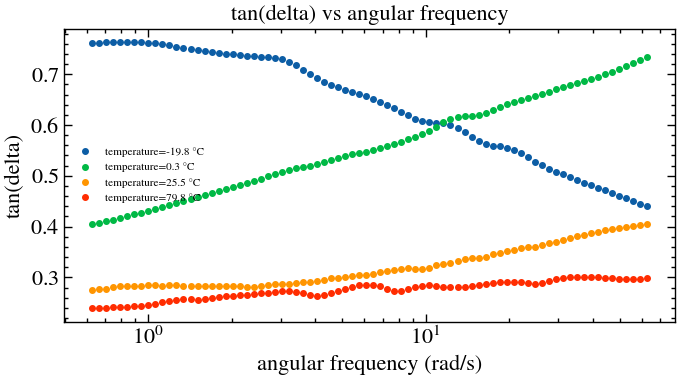

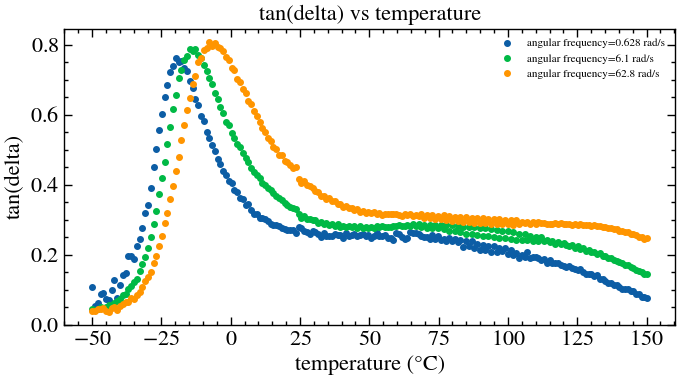

In [18]:
fig, ax = tan_delta.plot_slice_at_x([-20, 0, 25, 80], log_y_axis=False)
plt.show()
fig, ax = tan_delta.plot_slice_at_y([0.628, 6.28, 62.8], log_y_axis=False)
plt.show()

## Temperature–frequency map of the mutation number

`MutationNumber` (Tutorial 6) stores temperature and angular frequency with
each $\lvert \mathrm{Mu} \rvert$ value, so the same transform maps
$\lvert \mathrm{Mu}(T, \omega) \rvert$. Setting `vmax=0.15` saturates the
colour scale at the quasi-static limit: the brightest regions show where the
ramp is closest to the limit.

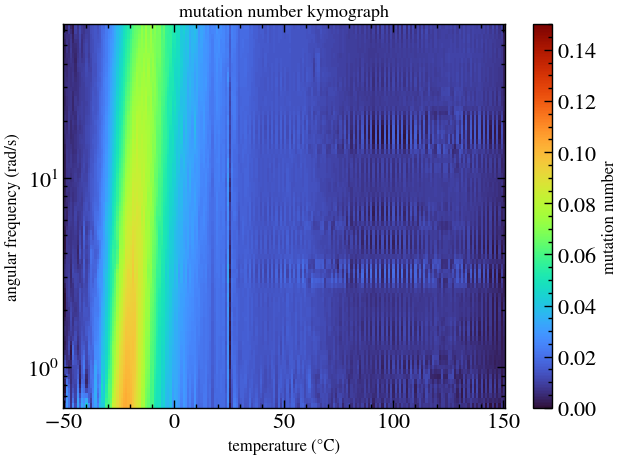

In [19]:
torch_mutation = MutationNumber(owch_length=10, absolute=True, dt_threshold=50)(torch)
mutation_map = Kymograph("mutation number", x="temperature", y="angular frequency")(torch_mutation)
fig, ax = mutation_map.plot(colormap="turbo", vmin=0, vmax=0.15)
plt.show()

$\lvert \mathrm{Mu} \rvert$ is highest across the glass transition, at all
frequencies, and stays well below 0.15 elsewhere. The narrow dark line at
25 °C is the turnaround between the two ramps, where the temperature
barely changes between consecutive chirps.

## References

- Geri, M., Keshavarz, B., Divoux, T., Clasen, C., Curtis, D. J. and McKinley,
  G. H., *Time-Resolved Mechanical Spectroscopy of Soft Materials via Optimally
  Windowed Chirps*, *Physical Review X* **8**, 041042 (2018).
  DOI: [10.1103/PhysRevX.8.041042](https://doi.org/10.1103/PhysRevX.8.041042).
- Mours, M. and Winter, H. H., *Time-resolved rheometry*, *Rheologica Acta*
  **33**, 385–397 (1994). DOI: [10.1007/BF00366581](https://doi.org/10.1007/BF00366581).
- Vadillo, D. C., Perego, A. et al., *TORCh: Thermally Optimised Ramped Chirp
  for time-temperature spectroscopy of polymers*, *Macromolecules* (2026).
  DOI: [10.1021/acs.macromol.6c00679](https://doi.org/10.1021/acs.macromol.6c00679).